# 01 - Data Cleaning and EDA

**Project:** Startup success scorer (classification + K-Means / DBSCAN clustering)
**Input:** `data/raw/yc_companies.csv` (never edited)
**Output:** `data/processed/yc_clean.csv` with exactly 12 columns:
`name, short_description, founded_year, batch, batch_year, industry, region, country, num_founders, team_size, status, label`

**Sections**
1. Explore
2. Clean
3. Keep companies founded in 2019 or earlier
4. Target column `label`
5. Group industries
6. Country from location
7. Leakage check
8. EDA
9. Save and final checks
10. Summary for the team

### Install the libraries (run once)

In [1]:
%pip install kagglehub ftfy

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import ftfy   # fixes broken text encoding: pip install ftfy

plt.rcParams.update({'figure.figsize': (8, 4), 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.3, 'axes.titleweight': 'bold'})
BLUE, ORANGE, GREEN, YELLOW = '#2a78d6', '#eb6834', '#1baf7a', '#eda100'

RAW_PATH = '../data/raw/yc_companies.csv'
OUT_PATH = '../data/processed/yc_clean.csv'

## 1. Explore

### 1.1 Load the data from Kaggle
The first run downloads the dataset from Kaggle and saves a copy as `data/raw/yc_companies.csv`. Later runs read that copy, and it is never edited.

In [3]:
import os, shutil
import kagglehub   # downloads Kaggle datasets: pip install kagglehub

if not os.path.exists(RAW_PATH):
    folder = kagglehub.dataset_download('supremesun/complete-ycombinator-dataset-from-2005-2024')
    os.makedirs(os.path.dirname(RAW_PATH), exist_ok=True)
    shutil.copy(os.path.join(folder, 'yc_companies.csv'), RAW_PATH)

df = pd.read_csv(RAW_PATH)
print(df.shape)
df.head()

(4974, 15)


,active_founders,batch,founded,industry,jobs,location,logo,long_description,name,region,short_description,status,tags,team_size,website
0,"Geffen Avraham,Onkar Singh",F24,2024.0,"Industrials,Aviation and Space",0,San Francisco,https://bookface-images.s3.amazonaws.com/small...,Bifrost Orbital is building the SSH for satell...,Bifrost Orbital,"San Francisco, CA, USA",24/7 and real-time connectivity for satellites,Active,"satellites,aerospace,telecommunications",0.0,https://bifrostorbital.com/
1,Josh Purtell,F24,2024.0,"B2B,Infrastructure",0,NaN,https://bookface-images.s3.amazonaws.com/small...,"You add a few decorators to your agent code, a...",Synth,NaN,We help AI agents learn from data.,Active,"artificial-intelligence,reinforcement-learning",1.0,https://www.usesynth.ai
2,"Collin Barnwell,Sabeek Pradhan",F24,2024.0,Government,0,San Francisco,https://bookface-images.s3.amazonaws.com/small...,Roundabout Technologies makes AI-powered traff...,Roundabout Technologies,"San Francisco, CA, USA",AI-powered traffic lights,Active,"govtech,computer-vision,transportation",2.0,https://roundabout.tech
3,"Huzaifa Sial,Ayush Tomar",F24,2024.0,"Healthcare,Healthcare IT",0,San Francisco,https://bookface-images.s3.amazonaws.com/small...,Helpcare builds AI Agents to take on coordinat...,Helpcare AI,"San Francisco, CA, USA",Helpcare gets more patient in the door with AI...,Active,"artificial-intelligence,health-tech,healthcare",NaN,https://helpcare.ai
4,Dexter Horthy,F24,2023.0,"B2B,Engineering, Product and Design",0,San Francisco,https://bookface-images.s3.amazonaws.com/small...,HumanLayer is an API and SDK that enables tool...,HumanLayer,"San Francisco, CA, USA",Human-in-the-Loop for AI Agents,Active,"developer-tools,generative-ai",1.0,https://humanlayer.dev


### 1.2 Column types

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4974 entries, 0 to 4973
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   active_founders    4940 non-null   object 
 1   batch              4974 non-null   object 
 2   founded            3899 non-null   float64
 3   industry           4974 non-null   object 
 4   jobs               4974 non-null   int64  
 5   location           4599 non-null   object 
 6   logo               4272 non-null   object 
 7   long_description   4629 non-null   object 
 8   name               4974 non-null   object 
 9   region             4684 non-null   object 
 10  short_description  4775 non-null   object 
 11  status             4974 non-null   object 
 12  tags               4218 non-null   object 
 13  team_size          4893 non-null   float64
 14  website            4973 non-null   object 
dtypes: float64(2), int64(1), object(12)
memory usage: 583.0+ KB


### 1.3 Missing values per column

In [5]:
missing = df.isna().sum().to_frame('missing')
missing['percent'] = (missing['missing'] / len(df) * 100).round(1)
missing.sort_values('missing', ascending=False)

,missing,percent
founded,1075,21.6
tags,756,15.2
logo,702,14.1
location,375,7.5
long_description,345,6.9
region,290,5.8
short_description,199,4.0
team_size,81,1.6
active_founders,34,0.7
website,1,0.0


### 1.4 Status values

In [6]:
df['status'].value_counts(dropna=False)

,count
status,
Active,3508
Inactive,851
Acquired,596
Public,19


### 1.5 Broken text

In [7]:
# text saved as UTF-8 but read as Latin-1, e.g. 'Café' -> 'CafÃ©'
broken = df['name'].str.contains('Ã|â€', na=False)
print('names with broken characters:', broken.sum())
df.loc[broken, ['name']].head()

names with broken characters: 8


,name
79,Ã ngstrÃ¶m AI
2011,Wheelys CafÃ©
2703,SantÃ©
3314,Compra RÃ¡pida
3339,TrÃ©bol


Some names, locations and founder names have broken characters. They are fixed in section 2.1.

### 1.6 Batch code without a year

In [8]:
# every batch should look like W15, S09 or F24
odd_batches = df.loc[~df['batch'].str.match(r'^[WSF]\d{2}$'), 'batch']
odd_batches.value_counts()

,count
batch,
IK12,77


`IK12` is Imagine K12, an EdTech program that joined YC in 2016. Its code has no year, so it needs special handling in section 2.4.

### 1.7 Repeated company names

In [9]:
print('repeated names:', df['name'].duplicated().sum())
df[df['name'] == 'Apollo'][['name', 'batch', 'status', 'website']]

repeated names: 60


,name,batch,status,website
3310,Apollo,W22,Active,https://www.apollofirst.xyz/
3686,Apollo,S21,Inactive,https://www.withapollo.com/
4973,Apollo,S11,Active,http://apollographql.com/


A repeated name does not mean a duplicate. Here three different companies are called Apollo, each in a different batch.

### 1.8 Exact duplicate rows

In [10]:
print('exact duplicate rows:', df.duplicated().sum())

exact duplicate rows: 0


There are no fully repeated rows, so duplicates must be checked with a better key in section 2.3.

**Section summary**
- 4,974 companies and 15 columns.
- Missing values: `founded` (1,075, 22%), `tags`, `logo`, `location`, `long_description`, `region`, `short_description`, `team_size`, and a few `active_founders`.
- `status` has 4 clean values: Active, Inactive, Acquired, Public. There is no variant like `closed`.
- Problems not listed in the task: broken characters in text, a batch code `IK12` with no year, and repeated company names.

## 2. Clean

### 2.1 Fix broken text
Some text was saved as UTF-8 and read as Latin-1, so `Wheelys Café` appears as `Wheelys CafÃ©`.

In [11]:
text_cols = ['name', 'short_description', 'region', 'location', 'active_founders']
for col in text_cols:
    df[col] = df[col].apply(lambda x: ftfy.fix_text(x).strip() if isinstance(x, str) else x)

print('names still broken:', df['name'].str.contains('Ã|â€', na=False).sum())
df.loc[broken, 'name'].head(3)

names still broken: 0


,name
79,Ångström AI
2011,Wheelys Café
2703,Santé


### 2.2 Normalize `status`

In [12]:
df['status'] = df['status'].str.strip().str.lower()
df['status'].value_counts()

,count
status,
active,3508
inactive,851
acquired,596
public,19


### 2.3 Remove duplicates

In [13]:
print('exact duplicate rows:', df.duplicated().sum())
df = df.drop_duplicates()

exact duplicate rows: 0


#### Same name, same batch, same website
These rows are the same company listed twice. We keep the copy with the most filled columns, so no information is lost.

In [14]:
key = ['name', 'batch', 'website']
df['filled_columns'] = df.notna().sum(axis=1)
df[df.duplicated(subset=key, keep=False)][key + ['team_size', 'filled_columns']]

,name,batch,website,team_size,filled_columns
536,Lokal,S19,https://www.getlokalapp.com,NaN,13
674,Lokal,S19,https://www.getlokalapp.com,24.0,13


In [15]:
df = (df.sort_values('filled_columns', ascending=False)
        .drop_duplicates(subset=key)
        .sort_index()
        .drop(columns='filled_columns'))
print('rows left:', len(df))

rows left: 4973


Lokal was listed twice. The kept copy has `team_size = 24`; the dropped copy had no team size.

#### A repeated name alone is not a duplicate
Different companies can share a name. For example, two different companies called Castle were both in W16:

In [16]:
df[df['name'] == 'Castle'][['name', 'batch', 'location', 'short_description']]

,name,batch,location,short_description
1630,Castle,W16,"Detroit, MI",Castle manages rental homes using automation a...
1681,Castle,W16,San Francisco,Block bots & bad behavior


#### Names that differ only in case, spaces or punctuation
`FitHub` and `Fithub` are not caught by the checks above, because the names are not exactly equal. We compare names after removing case, spaces and punctuation.

In [17]:
simple_name = df['name'].str.lower().str.replace(r'[^a-z0-9]', '', regex=True)
spellings = df.groupby(simple_name)['name'].transform('nunique')
similar = df[spellings > 1].assign(simple_name=simple_name).sort_values('simple_name')
similar[['name', 'batch', 'status', 'website', 'location', 'team_size', 'short_description']]

,name,batch,status,website,location,team_size,short_description
4294,FitHub,W21,active,https://www.fithub.com.co,"Barranquilla, Colombia",60.0,The one-stop shop for healthy products
4856,Fithub,W10,inactive,http://fithub.com,NaN,0.0,NaN
289,Henry,S24,active,http://www.henry.ai,New York,3.0,Automating Deal Decks for Commercial Real Esta...
4564,HENRY,S20,active,https://www.soyhenry.com/hiring-en,"Buenos Aires, Argentina",100.0,We train the best software engineers & data sc...
80,Miru,S24,active,https://www.miruml.com,San Francisco,3.0,Deployment infrastructure for robotics and IoT
1063,miru,W18,inactive,https://www.miruhome.com,San Francisco,1.0,Experience any piece of furniture in AR
1474,TapToLearn,IK12,active,https://www.taptolearn.com,"Menlo Park, CA",11.0,NaN
4731,Tap to Learn,W12,inactive,http://taptolearn.com,"Menlo Park, CA",11.0,Games For Education


- **FitHub / Fithub:** different companies. Different batch (W21 vs W10), website (`fithub.com.co` vs `fithub.com`) and founders.
- **HENRY / Henry:** different companies. A coding school in Buenos Aires vs a real-estate tool in New York.
- **Miru / miru:** different companies. Robotics infrastructure vs an AR furniture app.
- **Tap to Learn / TapToLearn:** the **same** company, checked below.

In [18]:
tap = df[simple_name == 'taptolearn']
print('same long description:', tap['long_description'].nunique() == 1)
tap[['name', 'batch', 'status', 'website', 'location', 'team_size', 'active_founders']]

same long description: True


,name,batch,status,website,location,team_size,active_founders
1474,TapToLearn,IK12,active,https://www.taptolearn.com,"Menlo Park, CA",11.0,NaN
4731,Tap to Learn,W12,inactive,http://taptolearn.com,"Menlo Park, CA",11.0,"Priyanthy Aprain Srampical,Sreejit Jayanthan,A..."


Both rows have the same website domain, city, team size and long description, but one is `inactive` (W12) and the other `active` (IK12). The same company would appear once as label 0 and once as label 1.

We keep the W12 row because it has the founders and a short description, and the IK12 row has neither. This choice decides the label of this company, so it is listed as an open question for the team.

In [19]:
df = df[~((df['name'] == 'TapToLearn') & (df['batch'] == 'IK12'))]
print('rows left:', len(df))

rows left: 4972


### 2.4 `batch_year`
`W15 -> 2015`, `S09 -> 2009`, `F24 -> 2024`.

`IK12` is **Imagine K12**, an EdTech accelerator that joined YC in 2016 (77 companies). Its code has no year, so we use **2013**, the median founding year of the IK12 companies that have one. All of them are older than 2017, so this choice does not change who passes the 2019 filter.

In [20]:
df['batch_year'] = 2000 + pd.to_numeric(df['batch'].str[1:], errors='coerce')   # 'IK12' -> NaN
print('IK12 median founded year:', df.loc[df['batch'] == 'IK12', 'founded'].median())
df.loc[df['batch'] == 'IK12', 'batch_year'] = 2013
df['batch_year'] = df['batch_year'].astype(int)
df['batch_year'].describe()

IK12 median founded year: 2013.0


,batch_year
count,4972.000000
mean,2019.080249
std,4.146798
min,2005.000000
25%,2017.000000
50%,2020.000000
75%,2022.000000
max,2024.000000


### 2.5 `founded_year`
If `founded` is missing, use `batch_year`.

#### Why is `batch_year` a good guess for a missing `founded`?
We check the companies where both years are known: how far apart are they?

In [21]:
known = df[df['founded'].notna()]
years_before_yc = known['batch_year'] - known['founded']

print(f'founded in the same year as the batch:     {(years_before_yc == 0).mean():.0%}')
print(f'founded 0 or 1 year before the batch:      {years_before_yc.between(0, 1).mean():.0%}')
print(f'founded after the batch year:              {(years_before_yc < 0).mean():.0%}')

founded in the same year as the batch:     40%
founded 0 or 1 year before the batch:      81%
founded after the batch year:              3%


Most companies join YC in the year they are founded or one year later. So when `founded` is missing, `batch_year` is usually right or off by about one year.

#### Does the fill change who passes the 2019 filter?

In [22]:
missing = df['founded'].isna()
print('missing founded, batch 2019 or earlier:', (missing & (df['batch_year'] <= 2019)).sum())
print('missing founded, batch 2020 or later:  ', (missing & (df['batch_year'] >= 2020)).sum())

missing founded, batch 2019 or earlier: 997
missing founded, batch 2020 or later:   77


Most missing values (997 of 1,074) are in batches up to 2019, so those companies pass the filter either way.
The 77 companies from 2020+ batches will be removed. A few of them may really be founded in 2019, but they joined YC recently, and that is exactly the age effect we want to avoid (section 8.7). Removing them does no harm.

In [23]:
df['founded_missing'] = df['founded'].isna()     # kept only for the leakage check, not saved
df['founded_year'] = df['founded'].fillna(df['batch_year']).astype(int)
print('filled from batch:', df['founded_missing'].sum())
print('founded after batch year (kept as is):', (df['founded_year'] > df['batch_year']).sum())

filled from batch: 1074
founded after batch year (kept as is): 102


### 2.6 `team_size = 0` means unknown

In [24]:
zero = df['team_size'] == 0
print('companies with team_size = 0:', zero.sum())
df.loc[zero, 'status'].value_counts()

companies with team_size = 0: 111


,count
status,
inactive,79
acquired,18
active,14


An active or acquired company cannot have 0 people, so 0 is a placeholder for "unknown", like the empty values. We turn it into a missing value, and section 9 fills it with the median together with the other missing team sizes.

In [25]:
df['team_size'] = df['team_size'].replace(0, np.nan)
print('missing team_size now:', df['team_size'].isna().sum())

missing team_size now: 191


**Note: `team_size` is approximate.** Some values appear much more often than their neighbours:

In [26]:
df['team_size'].value_counts().reindex([10, 11, 12, 50, 51, 52, 200, 201, 202, 500, 501, 502]).fillna(0).astype(int)

,count
team_size,
10,162
11,235
12,108
50,64
51,48
52,6
200,22
201,12
202,0


11, 51, 201 and 501 look like the lower end of size ranges ("11-50 employees", "51-200", "201-500"). Companies probably pick a range and the site stores its first number. Nothing to fix, but a team size of 11 may really mean anything from 11 to 50.

### 2.7 Placeholder descriptions

In [27]:
placeholders = ['-', 'TBD']
print(df.loc[df['short_description'].isin(placeholders), ['name', 'short_description']])
df['short_description'] = df['short_description'].replace(placeholders, np.nan)

                     name short_description
1738  Stitch Technologies                 -
2464            Airshared               TBD


These are not real descriptions, and the app would show them as text. They become missing values, and section 9 fills them with empty text.

**Section summary**
- Fixed broken characters in 5 text columns.
- `status` is lowercase with no spaces.
- No exact duplicate rows. Lokal was listed twice; we kept the more complete copy (with `team_size = 24`).
- Tap to Learn (W12, inactive) and TapToLearn (IK12, active) are the same company with opposite outcomes. We kept the W12 row.
- Names that differ only in case (FitHub / Fithub, HENRY / Henry, Miru / miru) were checked: they are different companies.
- `batch_year` was made from `batch`, and IK12 was set to 2013.
- 1,074 missing `founded` values were filled from `batch_year`. This is a good guess: 81% of companies with a known year were founded 0 or 1 year before their batch.
- 111 companies with `team_size = 0` were changed to missing, because 0 is not a real team size.
- `team_size` is approximate: values like 11, 51, 201 and 501 are the lower end of size ranges.
- 2 placeholder descriptions (`-` and `TBD`) were changed to missing.

## 3. Keep companies founded in 2019 or earlier
The data was scraped in November 2024, so this keeps companies that are at least 5 years old.

In [28]:
all_companies = df.copy()          # kept to compare before and after
df = df[df['founded_year'] <= 2019].copy()
print(f'{len(all_companies)} -> {len(df)} companies ({len(all_companies) - len(df)} removed)')

4972 -> 2559 companies (2413 removed)


**Section summary**
- 4,972 -> 2,559 companies. 2,413 companies founded in 2020 or later were removed.

## 4. Target column `label`

In [29]:
label_map = {'acquired': 1, 'public': 1, 'active': 1, 'inactive': 0}
df['label'] = df['status'].map(label_map)
print('rows with unknown status:', df['label'].isna().sum())
df = df.dropna(subset=['label'])
df['label'] = df['label'].astype(int)

print(df['label'].value_counts())

rows with unknown status: 0
label
1    1874
0     685
Name: count, dtype: int64


In [30]:
pd.crosstab(df['status'], df['label'], margins=True)

label,0,1,All
status,,,
acquired,0,530,530
active,0,1326,1326
inactive,685,0,685
public,0,18,18
All,685,1874,2559


**Section summary**
- **label = 1: 1,874 companies (73%). label = 0: 685 companies (27%).**
- No rows were dropped for an unknown status.
- Class 1 is 71% `active`, 28% `acquired` and 1% `public`.

## 5. Group industries
`industry` looks like `B2B,Infrastructure`. The first part is the main sector.

In [31]:
df['industry'] = df['industry'].str.split(',').str[0].str.strip()
df['industry'].value_counts()

,count
industry,
B2B,1004
Consumer,569
Healthcare,323
Fintech,247
Industrials,148
Education,146
Real Estate and Construction,82
Government,21
Unspecified,19


In [32]:
groups = {'B2B': 'B2B', 'Consumer': 'Consumer', 'Fintech': 'Fintech', 'Healthcare': 'Healthcare',
          'Education': 'Education', 'Industrials': 'Industrials', 'Real Estate and Construction': 'Real Estate'}
df['industry'] = df['industry'].map(groups).fillna('Other')
df['industry'].value_counts()

,count
industry,
B2B,1004
Consumer,569
Healthcare,323
Fintech,247
Industrials,148
Education,146
Real Estate,82
Other,40


**Section summary**
- 8 groups: B2B, Consumer, Healthcare, Fintech, Industrials, Education, Real Estate, Other.
- Other holds Government (21) and Unspecified (19).

## 6. Location: `country` and `region`

### 6.1 Country from `location`
`location` comes in three forms:
- `London, United Kingdom`: the country is the last part.
- `Austin, TX` or `NY`: a US state code, so the country is the United States.
- `San Francisco`: a US city with nothing after it.

If `location` is empty, we take the country from the original `region`. Country names are full English names, as in `docs/schema.md` (`United States`, not `USA`).

In [33]:
us_cities = ['San Francisco', 'New York', 'Palo Alto', 'Mountain View', 'Boston']

def get_country(loc):
    if pd.isna(loc):
        return None
    if loc.startswith('Remote'):        # 'Remote, OR' is remote, not the state of Oregon
        return 'Remote'
    last = loc.split(',')[-1].strip()
    if loc in us_cities or (len(last) == 2 and last.isupper()):    # 'CA', 'NY', ...
        return 'United States'
    if last in ['USA', 'US']:
        return 'United States'
    return last

df['country'] = df['location'].apply(get_country)
df['country'] = df['country'].fillna(df['region'].apply(get_country)).fillna('Unknown')
df['country'].value_counts().head(10)

,count
country,
United States,1887
Canada,105
Unknown,94
India,82
United Kingdom,65
Mexico,37
Nigeria,28
Singapore,21
Brazil,19


In [34]:
# check: the country from location should match the country in the original region
both = df['region'].notna() & (df['country'] != 'Unknown')
match = (df.loc[both, 'region'].apply(get_country) == df.loc[both, 'country']).mean()
print(f'match with region: {match:.1%}')

match with region: 100.0%


### 6.2 `region` as a world region
The task file says "keep `region` as it is", but `docs/schema.md` defines `region` as a world region (United States, Europe, Asia, Latin America, Africa, Middle East, Other), and both model roles use `region` as a feature.

The original `region` is a city (`San Francisco, CA, USA`) with 289 different values. One-hot encoding it would create 289 columns, most with only a few companies. So we follow the schema and build `region` from `country`.

In [35]:
print('original region values:', df['region'].nunique())

world_regions = {
    'United States': ['United States'],
    'Europe': ['United Kingdom', 'France', 'Germany', 'Denmark', 'Poland', 'Netherlands', 'Spain', 'Slovenia',
               'Sweden', 'Norway', 'Ireland', 'Greece', 'Estonia', 'Austria', 'Switzerland', 'Ukraine',
               'Czech Republic', 'Latvia', 'Hungary', 'Russia', 'Finland', 'Romania', 'Italy', 'Portugal',
               'Belgium', 'Lithuania', 'Bulgaria', 'Croatia', 'Serbia', 'Iceland', 'Luxembourg',
               'Czechia', 'Cyprus', 'Georgia'],
    'Asia': ['India', 'Singapore', 'Indonesia', 'China', 'Hong Kong', 'South Korea', 'Malaysia', 'Philippines',
             'Pakistan', 'Vietnam', 'Nepal', 'Bangladesh', 'Japan', 'Taiwan', 'Thailand', 'Sri Lanka'],
    'Latin America': ['Mexico', 'Brazil', 'Colombia', 'Argentina', 'Chile', 'Peru', 'Panama', 'Puerto Rico',
                      'Uruguay', 'Ecuador', 'Guatemala', 'Costa Rica', 'Bolivia', 'Venezuela', 'Dominican Republic'],
    'Africa': ['Nigeria', 'Egypt', 'Kenya', 'South Africa', 'Ghana', 'Morocco', 'Senegal', 'Seychelles', 'Uganda',
               'Rwanda', 'Ethiopia', 'Tanzania', 'Algeria', 'Tunisia', 'Cameroon', "Cote d'Ivoire",
               "Côte D'Ivoire", 'Ivory Coast', 'Zambia', 'Namibia', 'Congo (Dem. Rep.)',
               'Democratic Republic of the Congo'],
    'Middle East': ['Israel', 'United Arab Emirates', 'Saudi Arabia', 'Iraq', 'Turkey', 'Jordan', 'Lebanon',
                    'Qatar', 'Bahrain', 'Kuwait', 'Oman'],
}
country_to_region = {country: region for region, countries in world_regions.items() for country in countries}

df['region'] = df['country'].map(country_to_region).fillna('Other')
df['region'].value_counts()

original region values: 289


,count
region,
United States,1887
Other,220
Asia,146
Europe,144
Latin America,100
Africa,48
Middle East,14


In [36]:
# which countries ended up in Other?
df.loc[df['region'] == 'Other', 'country'].value_counts()

,count
country,
Canada,105
Unknown,94
Remote,15
Australia,4
New Zealand,2


**Section summary**
- `country`: 62 values with full English names. The United States has 1,887 companies (74%).
- 94 companies have no location at all, so their country is `Unknown`.
- `country` matches the original `region` in 100% of the rows where both exist.
- `region`: 7 world regions, as in `docs/schema.md`. `Other` holds Canada (105), the `Unknown` companies (94), `Remote` (15), Australia and New Zealand.
- `Remote, OR` (2 companies here) is treated as `Remote`, not as the state of Oregon.
- Egypt is counted in Africa, and Turkey in the Middle East.

## 7. Leakage check
A leaking column gives the model the answer, usually because a closed company's page stopped being updated.

In [37]:
# num_founders: count of names. Empty field -> missing, not 0 (a company cannot have 0 founders)
df['num_founders'] = df['active_founders'].apply(
    lambda s: len([n for n in s.split(',') if n.strip()]) if isinstance(s, str) else np.nan)

df.groupby('label').agg(
    jobs_is_zero=('jobs', lambda x: (x == 0).mean()),
    team_size_median=('team_size', 'median'),
    team_size_zero_or_missing=('team_size', lambda x: ((x == 0) | x.isna()).mean()),
    founders_missing=('num_founders', lambda x: x.isna().mean()),
    founders_mean=('num_founders', 'mean'),
).T.round(2)

label,0,1
jobs_is_zero,1.00,0.82
team_size_median,2.00,18.00
team_size_zero_or_missing,0.12,0.03
founders_missing,0.04,0.00
founders_mean,1.91,1.92


In [38]:
print('Success rate when a value is missing vs present:')
checks = {'founded': df['founded_missing'],
          'location (country Unknown)': df['country'] == 'Unknown',
          'short_description': df['short_description'].isna(),
          'active_founders': df['num_founders'].isna()}
for name, missing in checks.items():
    print(f'  {name:28s} missing: {df.loc[missing, "label"].mean():.0%}   present: {df.loc[~missing, "label"].mean():.0%}')

Success rate when a value is missing vs present:
  founded                      missing: 51%   present: 87%
  location (country Unknown)   missing: 21%   present: 75%
  short_description            missing: 35%   present: 76%
  active_founders              missing: 6%   present: 74%


### Hidden leak: does filling `founded` create a new signal?
After the fill, every company that had a missing `founded` now has `founded_year == batch_year`. A missing `founded` is linked to failure (51% success vs 87%), so this equality might carry the same signal.

In [39]:
same_year = df['founded_year'] == df['batch_year']
df.groupby(same_year)['label'].agg(['count', 'mean']).rename(
    index={True: 'founded_year == batch_year', False: 'founded_year != batch_year'},
    columns={'count': 'companies', 'mean': 'success rate'}).round(2)

,companies,success rate
founded_year != batch_year,1110,0.88
founded_year == batch_year,1449,0.62


It does: companies with the same year succeed 62% of the time, vs 88% for the rest.

A model that uses **both** `founded_year` and `batch_year`, or a feature like `batch_year - founded_year`, can see that a difference of 0 often means "was missing". It would learn the leak indirectly.

**Rule for the team:** use only one of the two columns, and do not build a feature from their difference. They are also 93% correlated (section 8.9), so the model loses almost nothing.

In [40]:
df = df.drop(columns=['jobs'])

**Section summary**

| Column | Finding | Action |
|---|---|---|
| `jobs` | 100% of closed companies have 0 jobs | Dropped |
| `team_size` | Median 2 for closed vs 18 for successful. It is the size today, not at founding | Kept, but risky: train with and without it |
| `active_founders` | Mean count is the same (1.9 vs 1.9). An empty field means 6% success | Missing `num_founders` is filled with the median (2) when saving, so the empty field cannot leak |
| Missing `founded` | 51% success when missing vs 87% when present | Already filled from batch. Do not add a "was missing" feature |
| `founded_year == batch_year` | 62% success vs 88%, because filled rows always have the same year | Use only one of the two years. No difference feature |
| Missing location | `country = Unknown` has 21% success | These companies are in `region = Other`, which pulls Other down. Be careful when reading Other |
| Missing `short_description` | 35% success when missing vs 76% | Filled with `''`. The schema says it is for the app only, not a model feature |

The pattern is the same everywhere: when a startup dies, its YC page stops being updated, so empty fields reveal the answer.

## 8. EDA

In [41]:
def plot_success_rate(col, title, order=None, data=None):
    data = df if data is None else data
    rates = data.groupby(col)['label'].agg(['mean', 'count'])
    rates = rates.loc[order] if order is not None else rates.sort_values('mean')
    ax = (rates['mean'] * 100).plot.barh(color=BLUE, figsize=(8, 0.4 * len(rates) + 1),
                                          title=title + '  (dashed line = overall)')
    ax.axvline(df['label'].mean() * 100, color='gray', linestyle='--')
    for i, (m, n) in enumerate(zip(rates['mean'], rates['count'])):
        ax.text(m * 100 + 1, i, f'{m:.0%} (n={n})', va='center', fontsize=9)
    ax.set_xlim(0, 110); ax.set_xlabel('% success'); ax.set_ylabel('')
    plt.show()

### 8.1 How balanced is the label?

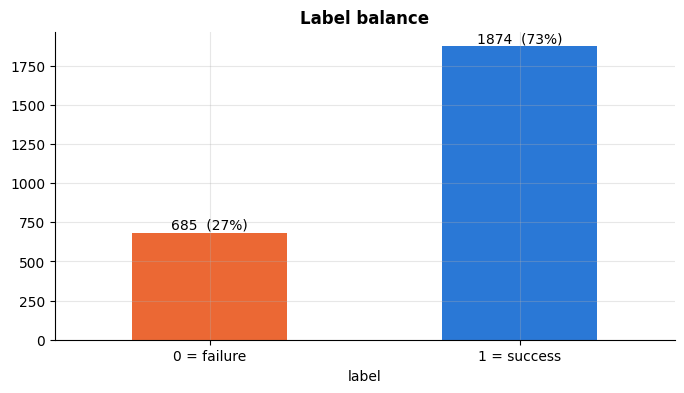

In [42]:
counts = df['label'].value_counts().sort_index()
ax = counts.plot.bar(color=[ORANGE, BLUE], rot=0, title='Label balance')
ax.set_xticklabels(['0 = failure', '1 = success'])
for i, v in enumerate(counts):
    ax.text(i, v + 20, f'{v}  ({v / counts.sum():.0%})', ha='center')
plt.show()

**Insight:** 73% success vs 27% failure. A model that always says "success" gets 73% accuracy, so use a stratified split, `class_weight='balanced'`, and report F1 and ROC-AUC.

### 8.2 Which industries succeed the most?

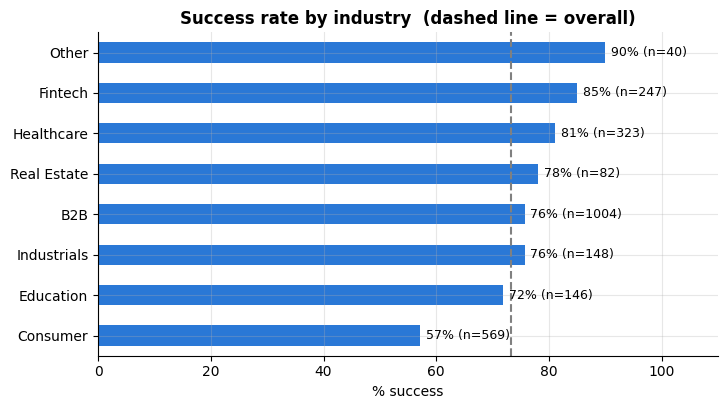

In [43]:
plot_success_rate('industry', 'Success rate by industry')

**Insight:** Consumer is clearly the weakest (57%). Fintech (85%) and Healthcare (81%) are the strongest, so industry is a useful feature.

### 8.3 Does the region matter?

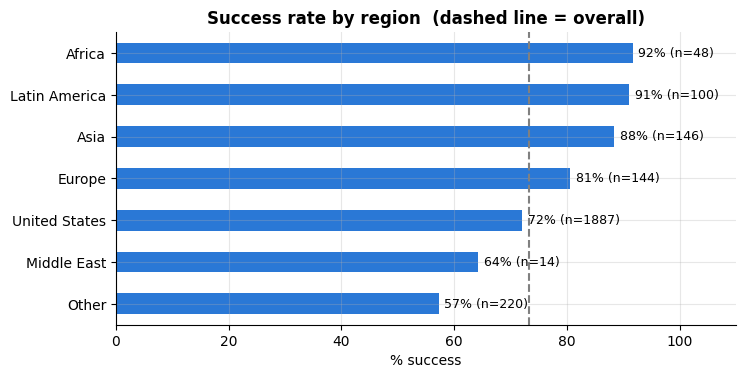

,count,mean
region,,
United States,1887,0.72
Other,220,0.57
Asia,146,0.88
Europe,144,0.81
Latin America,100,0.91
Africa,48,0.92
Middle East,14,0.64


In [44]:
plot_success_rate('region', 'Success rate by region')
df.groupby('region')['label'].agg(['count', 'mean']).round(2).sort_values('count', ascending=False)

**Insight:** The United States (72%) is close to the overall rate. Europe (81%), Asia (88%), Latin America (91%) and Africa (92%) are higher. The Middle East has only 14 companies, so its 64% is not reliable. `Other` (57%) is pulled down by the 94 `Unknown` companies (21% success), which is leakage, not a real place.

### 8.4 Does the number of founders matter?

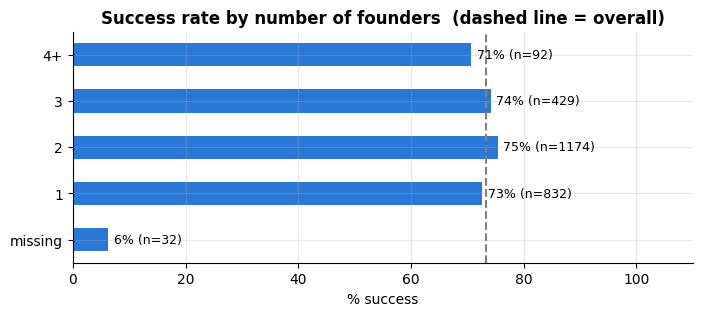

In [45]:
df['founders_group'] = df['num_founders'].clip(upper=4).map({1: '1', 2: '2', 3: '3', 4: '4+'}).fillna('missing')
plot_success_rate('founders_group', 'Success rate by number of founders', order=['missing', '1', '2', '3', '4+'])
df = df.drop(columns=['founders_group'])

**Insight:** 1, 2, 3 and 4+ founders are almost the same (71-75%), so the number of founders barely matters. The `missing` group (6%) is leakage from dead pages.

### 8.5 How is team size distributed for each label?

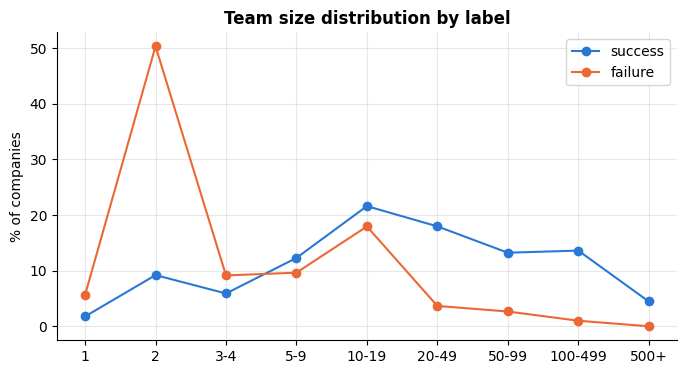

In [46]:
bins = [1, 2, 3, 5, 10, 20, 50, 100, 500, 10000]
fig, ax = plt.subplots()
for label, color, name in [(1, BLUE, 'success'), (0, ORANGE, 'failure')]:
    sizes = df.loc[df['label'] == label, 'team_size'].dropna()
    share = pd.cut(sizes, bins, right=False).value_counts(normalize=True, sort=False) * 100
    ax.plot(range(len(share)), share.values, marker='o', color=color, label=name)
ax.set_xticks(range(len(bins) - 1), ['1', '2', '3-4', '5-9', '10-19', '20-49', '50-99', '100-499', '500+'])
ax.set_title('Team size distribution by label'); ax.set_ylabel('% of companies'); ax.legend()
plt.show()

**Insight:** Half of the failed companies (with a known size) have exactly 2 people, while successful ones spread from 10 to 500. This is a strong signal, but mostly because it is the size today (see section 7). Companies with `team_size = 0` are not in this chart, because 0 now counts as missing (section 2.6).

### 8.6 Is there still an age effect after the 2019 filter?

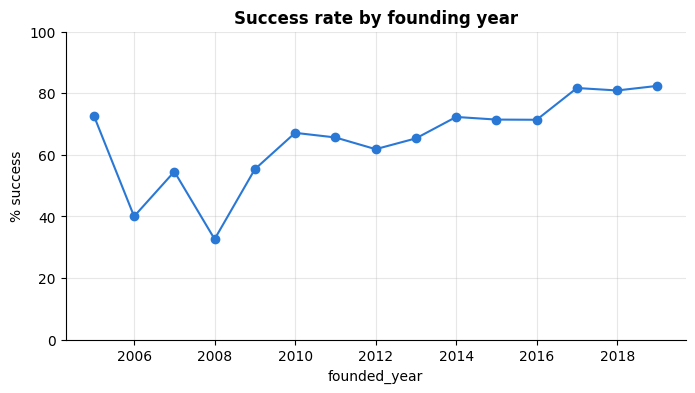

In [47]:
by_year = df.groupby('founded_year')['label'].mean() * 100
ax = by_year.plot(marker='o', color=BLUE, title='Success rate by founding year')
ax.set_ylim(0, 100); ax.set_ylabel('% success')
plt.show()

**Insight:** Yes. Companies founded in 2006-2009 succeed 33-55% of the time, while those from 2017-2019 reach 82%. Older companies had more years to fail, so `founded_year` will teach the model that newer is better.

### 8.7 Did some companies join YC after 2019?

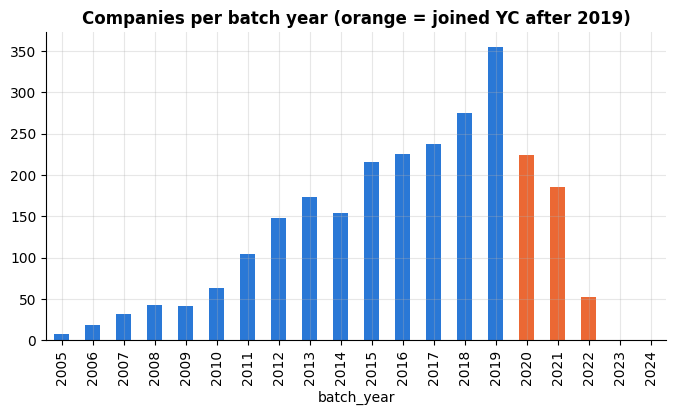

joined after 2019: 464 companies, 89% success
joined 2019 or before: 2095 companies, 70% success


In [48]:
late = df['batch_year'] > 2019
counts = df['batch_year'].value_counts().sort_index()
ax = counts.plot.bar(color=[ORANGE if y > 2019 else BLUE for y in counts.index],
                     title='Companies per batch year (orange = joined YC after 2019)')
plt.show()
print(f'joined after 2019: {late.sum()} companies, {df.loc[late, "label"].mean():.0%} success')
print(f'joined 2019 or before: {(~late).sum()} companies, {df.loc[~late, "label"].mean():.0%} success')

**Insight:** 464 companies (18%) were founded in 2019 or earlier but joined YC in 2020-2024. They succeed 89% of the time vs 70% for the rest, because their YC run is recent. The team should also try `batch_year <= 2019`.

### 8.8 How does each industry end?

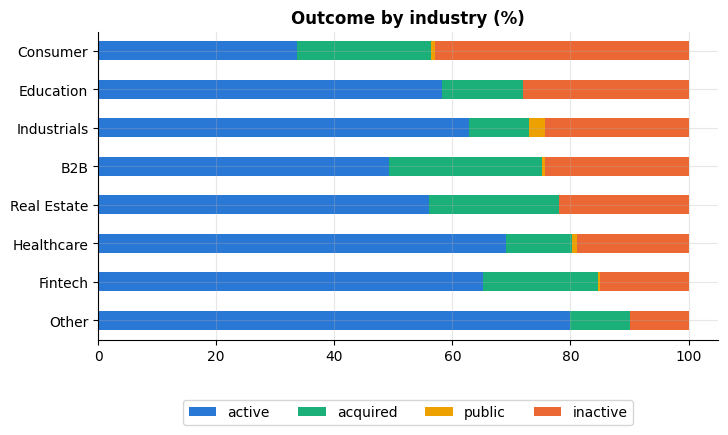

In [49]:
mix = pd.crosstab(df['industry'], df['status'], normalize='index')[['active', 'acquired', 'public', 'inactive']] * 100
ax = mix.sort_values('inactive').plot.barh(stacked=True, color=[BLUE, GREEN, YELLOW, ORANGE],
                                           title='Outcome by industry (%)')
ax.legend(ncol=4, loc='lower center', bbox_to_anchor=(0.5, -0.3)); ax.set_ylabel('')
plt.show()

**Insight:** B2B has the most acquisitions (26%), and Consumer has the most shutdowns (43%). Healthcare and Fintech succeed mostly by staying active.

### 8.9 What do the numeric features look like for clustering?

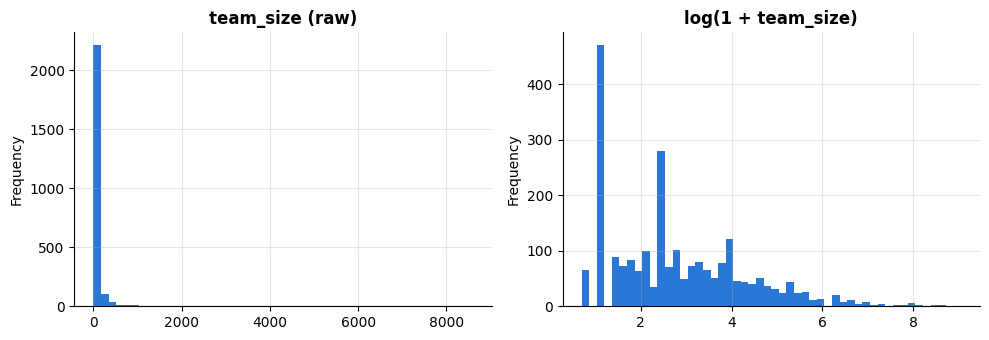

          name  team_size status
      DoorDash     8600.0 public
        Stripe     7000.0 active
        Airbnb     6132.0 public
      Coinbase     6112.0 public
EquipmentShare     5400.0 active


,founded_year,batch_year,num_founders,team_size
founded_year,1.00,0.93,-0.01,-0.08
batch_year,0.93,1.00,0.03,-0.07
num_founders,-0.01,0.03,1.00,0.05
team_size,-0.08,-0.07,0.05,1.00


In [50]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
df['team_size'].plot.hist(bins=50, ax=axes[0], color=BLUE, title='team_size (raw)')
np.log1p(df['team_size']).plot.hist(bins=50, ax=axes[1], color=BLUE, title='log(1 + team_size)')
plt.tight_layout(); plt.show()

print(df.nlargest(5, 'team_size')[['name', 'team_size', 'status']].to_string(index=False))
df[['founded_year', 'batch_year', 'num_founders', 'team_size']].corr().round(2)

**Insight:** `team_size` is very skewed (median 11, max 8,600). The biggest companies are DoorDash, Stripe and Airbnb, and DBSCAN will mark them as outliers unless `team_size` is log-transformed. `founded_year` and `batch_year` are 93% correlated, so a model only needs one of them.

**Section summary**
- **Label:** 73% / 27%, so the classes are imbalanced.
- **Industry:** the strongest real signal. Consumer is 57%, and Fintech and Healthcare are 81-85%.
- **Region:** the United States is close to the overall rate, and the other world regions are higher. `Other` is pulled down by the `Unknown` companies (leakage).
- **Founders:** barely matters (71-75%).
- **Team size:** very strong, but mostly leakage.
- **Age:** still affects the label. 464 late YC joiners are 89% successful.
- **For clustering:** log-transform `team_size`, scale every numeric feature, and use only one of `founded_year` and `batch_year`.

## 9. Save and final checks

In [51]:
cols = ['name', 'short_description', 'founded_year', 'batch', 'batch_year', 'industry',
        'region', 'country', 'num_founders', 'team_size', 'status', 'label']
clean = df[cols].reset_index(drop=True)

# fill what is left, so every column matches the types in docs/schema.md
print('before filling:', clean[['short_description', 'num_founders', 'team_size']].isna().sum().to_dict())
print(f"success rate of companies with a missing team_size: {clean.loc[clean['team_size'].isna(), 'label'].mean():.0%}")
clean['short_description'] = clean['short_description'].fillna('')
clean['num_founders'] = clean['num_founders'].fillna(clean['num_founders'].median()).astype(int)
clean['team_size'] = clean['team_size'].fillna(clean['team_size'].median()).astype(int)

# checks
assert list(clean.columns) == cols
assert clean.isna().sum().sum() == 0
assert clean['label'].isin([0, 1]).all()
assert clean['founded_year'].max() <= 2019
assert set(clean['region']) <= {'United States', 'Europe', 'Asia', 'Latin America', 'Africa', 'Middle East', 'Other'}

clean.to_csv(OUT_PATH, index=False)
print(clean.shape)
clean.isna().sum()

before filling: {'short_description': 184, 'num_founders': 32, 'team_size': 142}
success rate of companies with a missing team_size: 42%
(2559, 12)


,0
name,0
short_description,0
founded_year,0
batch,0
batch_year,0
industry,0
region,0
country,0
num_founders,0
team_size,0


In [52]:
clean.head()

,name,short_description,founded_year,batch,batch_year,industry,region,country,num_founders,team_size,status,label
0,Whatnot,Whatnot is the largest livestream shopping pla...,2019,W20,2020,Consumer,United States,United States,2,400,active,1
1,Ansa Biotechnologies,Next-generation DNA synthesis using enzymes,2018,W20,2020,Healthcare,United States,United States,2,72,active,1
2,Ochre Bio,RNA medicines for liver diseases,2019,W20,2020,Healthcare,Europe,United Kingdom,1,50,active,1
3,Jet Admin,No-code business app builder,2019,W20,2020,B2B,United States,United States,2,8,active,1
4,Jenfi,Jenfi provides revenue-based financing for dig...,2019,W20,2020,Fintech,Asia,Singapore,2,18,active,1


**Section summary**
- Saved 2,559 rows and 12 columns, with no missing values.
- Filled before saving: `short_description` with `''` (184), `num_founders` with the median 2 (32), `team_size` with the median 11 (142, including the former zeros).
- Companies with a missing `team_size` succeed only about 42% of the time, because most former zeros are dead companies. After the fill they look like any company with 11 people, so the model can no longer single them out. This is better than keeping 0, which gave the answer away.
- Note: an empty `short_description` is saved as empty text, but `pd.read_csv` reads it back as NaN. Use `fillna('')` when showing it in the app.

## 10. Summary for the team

**Data**
- 2,559 companies founded in 2019 or earlier. **label = 1: 1,874 (73%)**, **label = 0: 685 (27%)**.

**Cleaning (beyond the task)**
- Fixed broken characters in text.
- Kept the more complete copy of Lokal, and removed TapToLearn (IK12), a duplicate of Tap to Learn (W12) with the opposite label.
- Checked names that differ only in case (FitHub / Fithub and others): they are different companies.
- `team_size = 0` and the placeholder descriptions `-` and `TBD` are treated as missing.
- `team_size` is approximate: 11, 51, 201 and 501 are the lower end of size ranges.
- IK12 (Imagine K12) batch set to 2013.
- `num_founders` and `team_size` are filled with the median, not 0, so empty fields do not leak.
- `region` is a world region, as in `docs/schema.md`, and `country` uses full names (`United States`).

**Leakage**
- `jobs` was dropped.
- `team_size` is risky: train with and without it.
- Empty fields (founders, location, description) mean a dead company.
- Use only one of `founded_year` and `batch_year`, and never their difference: `founded_year == batch_year` hides the missing-`founded` leak.

**Supervised model**
- Use a stratified split, `class_weight='balanced'`, F1 and ROC-AUC.
- Features from the role file: `num_founders, team_size, founded_year, industry, region`. Industry is the strongest safe one.
- Age still affects the label, so also test `batch_year <= 2019`.

**Clustering (K-Means / DBSCAN)**
- Do not cluster on `label` or `status`.
- Log-transform `team_size`, scale numeric features, and one-hot encode `industry` and `region`.
- Expect DBSCAN to flag the giants (DoorDash, Stripe, Airbnb) as unusual.